## $\text{Hedging Strategy with NVIDIA}$

In [6]:
import numpy as np
from statsmodels import regression
import statsmodels.api as sm
import matplotlib.pyplot as plt
import yfinance as yf

In [8]:
start_date = "2026-01-01"
end_date = "2026-10-01"

In [107]:
asset = yf.download('NVDA', start=start_date, end=end_date)['Close']['NVDA']
benchmark = yf.download('SPY', start=start_date, end=end_date)['Close']['SPY']

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [108]:
asset.head()

Date
2026-01-02    188.409134
2026-01-05    187.680832
2026-01-06    186.802902
2026-01-07    188.668518
2026-01-08    184.608002
Name: NVDA, dtype: float64

In [109]:
asset_ret = asset.pct_change(1)[1:]
benchmark_ret = benchmark.pct_change(1)[1:]


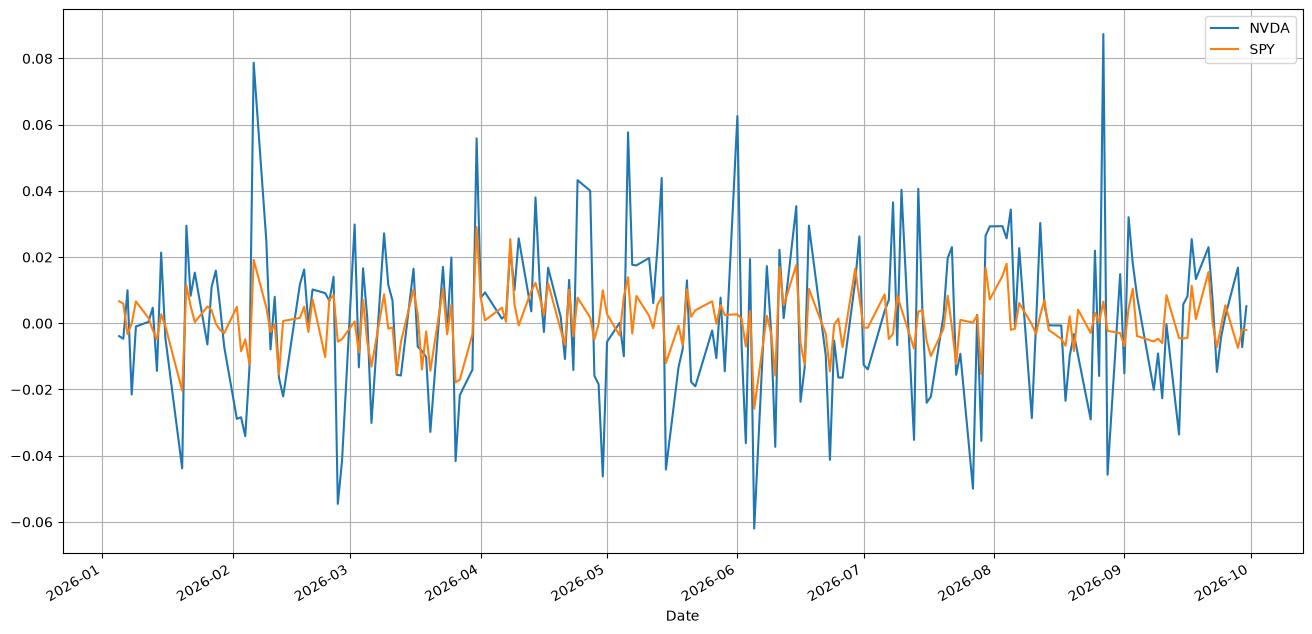

In [110]:
asset_ret.plot(figsize=(16,8))
benchmark_ret.plot()
plt.grid(True)
plt.legend()

## $\text{Regression for Alpha and Beta Values}$

Text(0, 0.5, 'NVDA Ret')

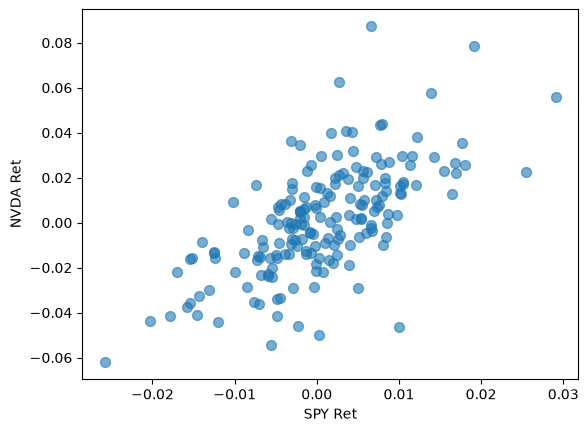

In [111]:
plt.scatter(benchmark_ret, asset_ret, alpha=0.6, s=50)
plt.xlabel('SPY Ret')
plt.ylabel('NVDA Ret')

In [112]:
NVDA = asset_ret.values
SPY = benchmark_ret.values

In [113]:
spy_constant = sm.add_constant(SPY)

In [114]:
spy_constant

array([[ 1.00000000e+00,  6.66017846e-03],
       [ 1.00000000e+00,  5.94725767e-03],
       [ 1.00000000e+00, -3.22350299e-03],
       [ 1.00000000e+00, -1.01511821e-04],
       [ 1.00000000e+00,  6.61347966e-03],
       [ 1.00000000e+00,  1.57034441e-03],
       [ 1.00000000e+00, -1.99951669e-03],
       [ 1.00000000e+00, -4.91531155e-03],
       [ 1.00000000e+00,  2.72328845e-03],
       [ 1.00000000e+00, -8.37764445e-04],
       [ 1.00000000e+00, -2.03568340e-02],
       [ 1.00000000e+00,  1.15411714e-02],
       [ 1.00000000e+00,  5.22303484e-03],
       [ 1.00000000e+00,  3.62832457e-04],
       [ 1.00000000e+00,  5.07816900e-03],
       [ 1.00000000e+00,  3.98429157e-03],
       [ 1.00000000e+00, -1.00649214e-04],
       [ 1.00000000e+00, -1.98443973e-03],
       [ 1.00000000e+00, -2.98253402e-03],
       [ 1.00000000e+00,  4.97121128e-03],
       [ 1.00000000e+00, -8.45533075e-03],
       [ 1.00000000e+00, -4.84383887e-03],
       [ 1.00000000e+00, -1.24893706e-02],
       [ 1.

In [115]:
model = regression.linear_model.OLS(NVDA, spy_constant).fit()

In [116]:
model.params

array([6.09775331e-05, 1.88863633e+00])

In [117]:
alpha, beta = model.params

In [118]:
alpha 

np.float64(6.097753312805142e-05)

In [119]:
beta

np.float64(1.8886363281570702)

## $\text{Plotting Alpha and Beta}$

Text(0, 0.5, 'NVDA Ret')

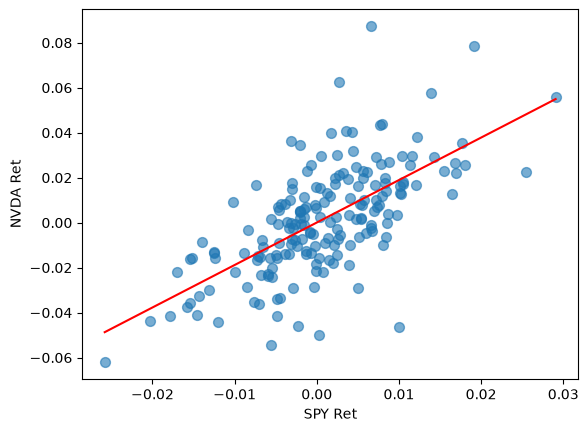

In [120]:
min_spy = benchmark_ret.values.min()
max_spy = benchmark_ret.values.max()

spy_line = np.linspace(min_spy, max_spy, 100)
y = spy_line*beta + alpha


plt.plot(spy_line, y, 'red')
plt.scatter(benchmark_ret, asset_ret, alpha=0.6, s=50)
plt.xlabel('SPY Ret')
plt.ylabel('NVDA Ret')

In [121]:
hedged = -1*(beta*benchmark_ret) + asset_ret

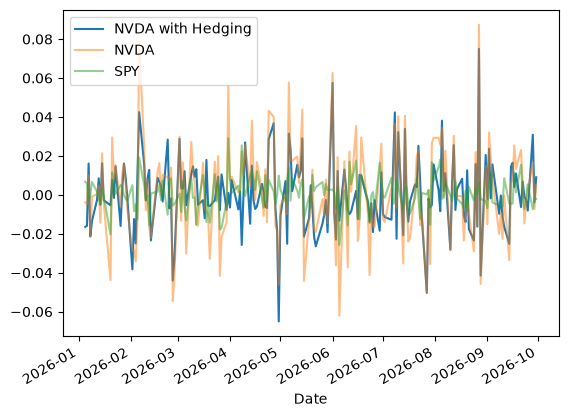

In [122]:
hedged.plot(label='NVDA with Hedging')
asset_ret.plot(alpha=0.5)
benchmark_ret.plot(alpha=0.5)
plt.legend()

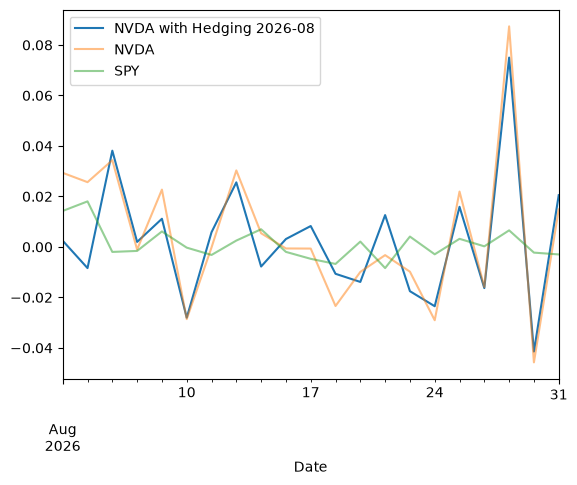

In [123]:
hedged.loc['2026-08'].plot(label='NVDA with Hedging 2026-08')
asset_ret.loc['2026-08'].plot(alpha=0.5)
benchmark_ret.loc['2026-08'].plot(alpha=0.5)
plt.legend()

In [124]:
def alpha_beta(benchmark_ret, stock):
    X = sm.add_constant(benchmark_ret)
    model = sm.OLS(stock, X).fit()
    params = np.asarray(model.params)   # fonctionne pour Series ET ndarray
    return params[0], params[1]

In [125]:
#2026 Cell

start_date = "2026-01-01"
end_date = "2026-10-01"

asset2026     = yf.download('NVDA', start=start_date, end=end_date)['Close']['NVDA']
benchmark2026 = yf.download('SPY',  start=start_date, end=end_date)['Close']['SPY']

asset_ret2026 = asset2026.pct_change(1)[1:]
benchmark_ret2026 = benchmark2026.pct_change(1)[1:]

aret_values = asset_ret2026.values
bret_values = benchmark_ret2026.values

alpha2026, beta2026 = alpha_beta(bret_values, aret_values)

print('2026 Values')
print('alpha : '+str(alpha2026))
print('beta : '+str(beta2026))

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

2026 Values
alpha : 6.097753312805142e-05
beta : 1.8886363281570702


In [126]:
portfolio = -1*beta2026*benchmark_ret2026 + asset_ret2026

In [127]:
alpha,beta = alpha_beta(benchmark_ret2026, portfolio)

In [128]:
print('Portfolio Alpha and Beta')
print('alpha : '+str(alpha))
print('beta : '+str(beta))


Portfolio Alpha and Beta
alpha : 6.09775331280516e-05
beta : 4.512563021098438e-17


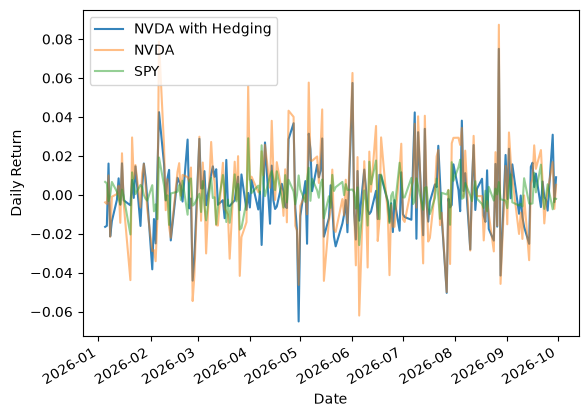

In [129]:
portfolio.plot(alpha=0.9, label='NVDA with Hedging')
asset_ret2026.plot(alpha=0.5)
benchmark_ret.plot(alpha=0.5)
plt.ylabel('Daily Return')
plt.legend()

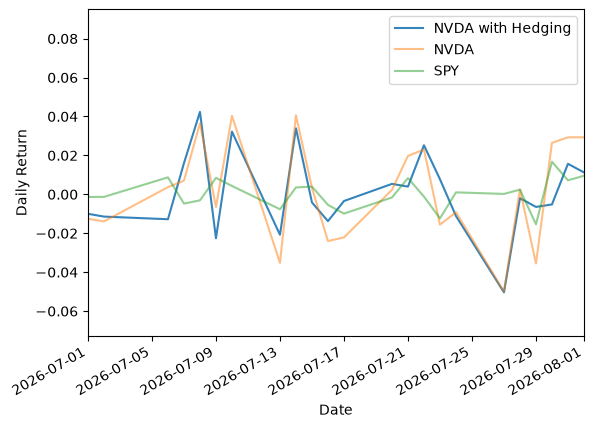

In [130]:
portfolio.plot(alpha=0.9, label='NVDA with Hedging')
asset_ret2026.plot(alpha=0.5)
benchmark_ret.plot(alpha=0.5)
plt.ylabel('Daily Return')
plt.xlim(['2026-07-01', '2026-08-01'])
plt.legend()

In [131]:
portfolio.mean()

np.float64(6.0977533128051636e-05)

In [132]:
asset_ret2026.mean()

np.float64(0.0013224943999387215)

In [133]:
portfolio.std()

np.float64(0.018282657158136758)

In [134]:
asset_ret2026.std()

np.float64(0.024102921800353814)